# **PLANETARY DEVASTATION**

## **by- Arhaan Manglik**

## ID: 2026A7PS0368P

### Necesarry imports

In [1]:
# Necessary imports
import pandas as pd
import numpy as np
filename = "NASA Data Only.csv"
target = "pl_eqt"

### Understanding the data and its correlation

In [2]:
df_1 = pd.read_csv(filename, comment="#")
df_1 = df_1.dropna(subset=[target])
r_1,c_1 = df_1.shape

# print()
# print()
# print("Number of records: ", r_1)
# print("Number of fields: ", c_1)

print("Dataset shape:", df_1.shape)

print("\nFirst five observations:")
print(df_1.head())

print("\nDataset information:")
df_1.info()

print("\nStatistical summary:")
print(df_1.describe())

print("\nMissing values:")
print(df_1.isnull().sum().sort_values(ascending=False).head(15))

Dataset shape: (5899, 174)

First five observations:
   rowid     pl_name  hostname pl_letter    hd_name    hip_name  \
0      1    11 Com b    11 Com         b  HD 107383   HIP 60202   
1      2    11 UMi b    11 UMi         b  HD 136726   HIP 74793   
2      3    14 And b    14 And         b  HD 221345  HIP 116076   
3      4    14 Her b    14 Her         b  HD 145675   HIP 79248   
4      5  16 Cyg B b  16 Cyg B         b  HD 186427   HIP 96901   

          tic_id                   gaia_dr2_id                   gaia_dr3_id  \
0   TIC 72437047  Gaia DR2 3946945413106333696  Gaia DR3 3946945413106333696   
1  TIC 230061010  Gaia DR2 1696798367260229376  Gaia DR3 1696798367260229376   
2  TIC 333225860  Gaia DR2 1920113512486282240  Gaia DR3 1920113512486282240   
3  TIC 219483057  Gaia DR2 1385293808145621504  Gaia DR3 1385293808145621504   
4   TIC 27533327  Gaia DR2 2135550755683407232  Gaia DR3 2135550755683407232   

   sy_snum  ...  pl_nnotes  st_nphot  st_nrvc st_nspec  pl_nesp

In [3]:
corr_mat1 = df_1.corr(method="pearson",numeric_only=True)

if target in corr_mat1.columns:
    print(corr_mat1[target].sort_values(ascending=False).iloc[1:11])
    print("\n\n")
    print(corr_mat1[target].sort_values(ascending=True).head(10))

tran_flag    0.332230
st_teff      0.323164
pl_insol     0.304163
st_lum       0.294584
st_vsin      0.279570
st_mass      0.263835
pl_rvamp     0.244634
obm_flag     0.224973
pl_tsm       0.211208
rowid        0.192876
Name: pl_eqt, dtype: float64



pl_ratdor     -0.472338
sy_umag       -0.324170
pl_trandur    -0.265262
pl_orbeccen   -0.247153
sy_gmag       -0.230510
sy_plx        -0.228729
ast_flag      -0.189402
sy_rmag       -0.175782
sy_pnum       -0.173152
sy_pm         -0.168383
Name: pl_eqt, dtype: float64


In [4]:
corr_mat2 = df_1.corr(method="spearman",numeric_only=True)

if target in corr_mat2.columns:
    print(corr_mat2[target].sort_values(ascending=False).iloc[1:11])
    print("\n\n")
    print(corr_mat2[target].sort_values(ascending=True).head(10))

pl_insol     0.939512
pl_esm       0.502274
tran_flag    0.408791
st_teff      0.364072
st_mass      0.331525
st_rad       0.319152
st_vsin      0.316390
st_lum       0.312468
sy_dist      0.309963
pl_rvamp     0.259293
Name: pl_eqt, dtype: float64



pl_ratdor    -0.860064
pl_orbper    -0.780777
pl_orbsmax   -0.691811
pl_angsep    -0.668208
pl_orbincl   -0.395010
sy_umag      -0.360489
st_rotp      -0.329660
sy_plx       -0.314730
st_dens      -0.308720
sy_pm        -0.306608
Name: pl_eqt, dtype: float64


#### Spearman correlation identifies stronger monotonic relationships for several orbital parameters, particularly orbital period and semi-major axis. This suggests that the relationships may not be adequately represented by simple linear associations on their original scales. Logarithmic transformations are therefore explored to improve the suitability of the data for Linear Regression. Correlation indicates association rather than causation.

#### On investigation, "pl_insol" is another way to represent equilibrium temperature
#### pl_esm is calculated using pl_eqt so cannot use it to predict pl_eqt as it becomes a circular relationship
#### tran_flag is just 0 or 1

### Putting constraints to remove outliers from the dataset

In [5]:
df_filtered = df_1[(df_1["pl_eqt"] > 50) & (df_1["pl_eqt"] < 3000) & (df_1["pl_orbsmax"] > 0.001) & (df_1["pl_orbsmax"] < 20)]

print("Records after filtering:", len(df_filtered))
print("Records removed:", len(df_1) - len(df_filtered))
df_1 = df_filtered.copy()

Records after filtering: 5533
Records removed: 366


### Inspecting and Selecting Relevant data features

In [6]:
# features = ["st_teff", "st_rad", "pl_orbsmax", "pl_orbper", "st_mass", "pl_rade", "pl_bmasse", "pl_orbeccen", "sy_dist"]
# features = [c for c in features if c in df_1.columns]

eda = df_1.copy()
eda = eda[eda[target] > 0]
print("Rows with a known temperature:", len(eda))

Rows with a known temperature: 5533


Text(0.5, 0, 'pl_eqt (K)')

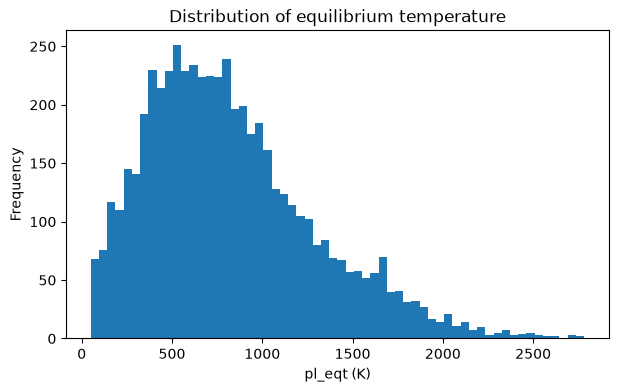

In [7]:
ax = eda[target].plot.hist(bins=60, figsize=(7, 4), title="Distribution of equilibrium temperature")
ax.set_xlabel("pl_eqt (K)")


Text(0.5, 0, 'log10(pl_eqt / K)')

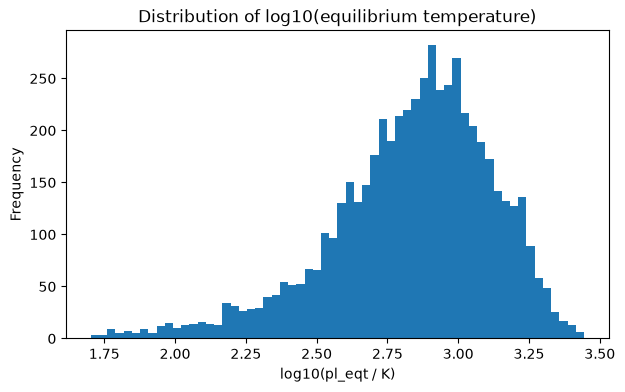

In [8]:
ax = np.log10(eda[target]).plot.hist(bins=60, figsize=(7, 4), title="Distribution of log10(equilibrium temperature)")
ax.set_xlabel("log10(pl_eqt / K)")

In [9]:
print("Original temperature skewness:", eda[target].skew())

print("Log temperature skewness:", np.log(eda[target]).skew())

Original temperature skewness: 0.8488544967746045
Log temperature skewness: -0.8365530111726501


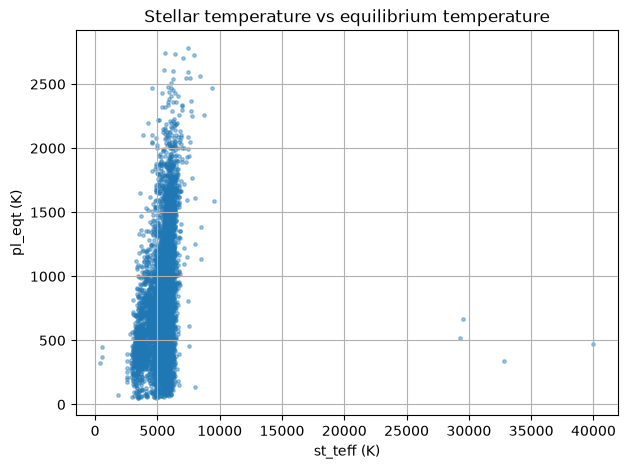

In [10]:
ax = eda.plot.scatter(x="st_teff", y=target, s=6, alpha=0.4, figsize=(7, 5),
                      title="Stellar temperature vs equilibrium temperature")
ax.set_xlabel("st_teff (K)")
ax.set_ylabel("pl_eqt (K)")
ax.grid(True)

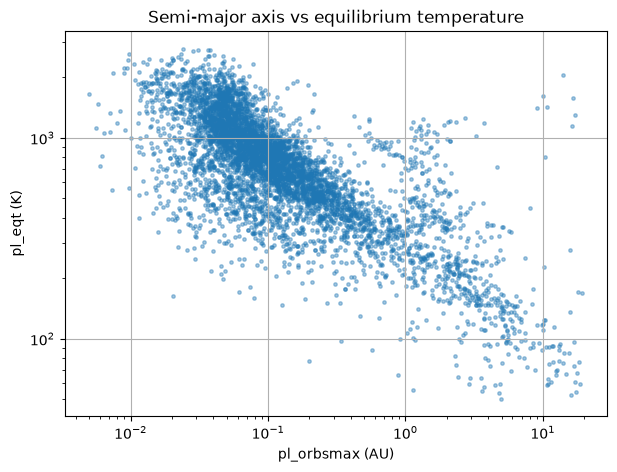

In [11]:
ax = eda.plot.scatter(x="pl_orbsmax", y=target, s=6, alpha=0.4, figsize=(7, 5), loglog=True,
                      title="Semi-major axis vs equilibrium temperature")
ax.set_xlabel("pl_orbsmax (AU)")
ax.set_ylabel("pl_eqt (K)")
ax.grid(True)

#### The temperature distribution is right-skewed. Most planets sit at moderate temperatures, with a long tail of very hot planets. The log-scale histogram is much more symmetric, and the two skewness values show it. This is the reason to model ln(T_eq) instead of T_eq.
#### Orbital distance is the dominant driver, and the relation is a power law. Temperature falls as semi-major axis grows, and the log-log scatter is close to a straight line. The slope shows how steep it is (physics predicts about −0.5 at fixed stellar properties; across all stars it will be noisier). Stellar temperature has a positive trend, but its raw scatter is blurry because planets at different distances orbit similar stars.

#### pl_insol is excluded because of its extremely strong association with equilibrium temperature, which raises concerns about target-related information leakage. pl_esm is also excluded because it is calculated using equilibrium temperature.

#### pl_ratdor is not selected because of its relatively high missingness, which would substantially reduce the available modelling sample. Orbital period is retained as a candidate for further comparison but is not included in the final feature set because semi-major axis provides a more direct representation of orbital distance.

#### The final model uses stellar effective temperature (st_teff), stellar radius (st_rad) and semi-major axis (pl_orbsmax). These features represent important characteristics of the host star and the planet's orbital environment.

### **Using 'st_teff', 'st_rad', 'pl_orbsmax' as params for the model**

In [12]:
cols_selected = ["st_teff", "pl_orbsmax", "st_rad"]

### **Gradient descent function**

In [13]:
def gradient_descent(X,y, lr=0.001, epochs=500000):

    assert not np.isnan(X).any().any(), "X contains NaN"
    X_log = np.log(X)
    y_log = np.log(y)
    assert not np.isnan(X_log).any().any(), "X_log contains NaN"
    
    ########################
    mean = np.mean(X_log, axis=0)
    std = np.std(X_log, axis=0)

    X_log = (X_log - np.mean(X_log, axis=0) + 1e-8) / (np.std(X_log, axis=0) + 1e-8)
    X_log = X_log.fillna(X_log.median())

    #######################
    X_final = np.asarray(X_log)
    y_final = np.asarray(y_log).reshape(-1,1)

    assert not np.isnan(X_final).any(), "X_final contains NaN"
    assert not np.isnan(y_final).any(), "y_final contains NaN"

    m,n = X_final.shape

    weights = np.zeros((n,1))
    bias = 0.0

    for _ in range(epochs):
        if (_ % (epochs//100) == 0):
            # print(_/(epochs/100), "%")
            pass
        y_pred = np.dot(X_final,weights) + bias

        err = y_pred - y_final
        dw = (1/m) * np.dot(X_final.T, err)
        db = (1/m) * np.sum(err)

        assert not np.isnan(dw).any(), "dw contains NaN values!"

        weights -= lr*dw
        bias -= lr*db
    l1 = weights.flatten()
    print("Learned weights: ")
    print("For st_teff: ", l1[0])
    print("For pl_orbsmax: ", l1[1])
    print("For st_rad: ", l1[2])
    print("Bias: ", bias)
        
    return weights.flatten(), bias, mean, std

### **Prediction function**

In [14]:
def predict(X, weights, bias, mean, std):
    X_log = np.log(X)

    X_log = (X_log - mean) / (std + 1e-8)

    X_new = np.asarray(X_log)
    prediction = np.dot(X_new, weights) + bias
    return np.exp(prediction), prediction

### **Evaluate function**

In [15]:
def evaluate(temp_act, temp_pred):
    ta = np.asarray(temp_act).flatten()
    tp = np.asarray(temp_pred).flatten()

    diff = ta - tp

    mae = np.mean(np.abs(diff))

    rmse = np.sqrt(np.mean(diff**2))

    ssres = np.sum(diff**2)
    sstot = np.sum((ta - np.mean(ta))**2)
    r2 = 1 - ssres/(sstot + 1e-8)

    return mae, rmse, r2

### **Training the model and evaluating its predictions**

In [16]:
df=pd.read_csv(filename, comment="#")
df_new = df[(df["pl_eqt"] > 50) & (df["pl_eqt"] < 3000) & (df["pl_orbsmax"] > 0.001) & (df["pl_orbsmax"] < 20)].copy()

df_new = df_new.dropna(subset=cols_selected + [target])
df_new = df_new[(df_new[cols_selected+[target]] > 0).all(axis=1)]

df_new = df_new.sample(frac=1, random_state=21).reset_index(drop=True)


split = int(0.8 * len(df_new))

df_train = df_new.iloc[:split]
df_test = df_new.iloc[split:]

print(f"Training rows: {len(df_train)}  |  Testing rows: {len(df_test)}")

X_train = df_train[cols_selected]
y_train = df_train[target]
X_test = df_test[cols_selected]
y_test = df_test[target]


w, b, mean, std = gradient_descent(X_train, y_train)


train_pred, train_log_pred = predict(X_train, w, b, mean, std)
test_pred, test_log_pred = predict(X_test, w, b, mean, std)

print("\n\nModel performance...")
print("Training data: ")
mae, rmse, r2 = evaluate(y_train.values, train_pred)
print(f"MAE: {mae}\nRMSE: {rmse}\nR2: {r2}\n\n")


print("Testing data: ")
mae, rmse, r2 = evaluate(y_test.values, test_pred)
print(f"MAE: {mae}\nRMSE: {rmse}\nR2: {r2}\n\n")

Training rows: 4411  |  Testing rows: 1103
Learned weights: 
For st_teff:  0.1681561669488958
For pl_orbsmax:  -0.6484804864010573
For st_rad:  0.32343741345160015
Bias:  6.539371301966119


Model performance...
Training data: 
MAE: 56.332845002519925
RMSE: 113.09371917762917
R2: 0.9418932940997351


Testing data: 
MAE: 53.74364560666188
RMSE: 89.24327694009914
R2: 0.9612469161769333




### **Predicted vs Actual Graph**

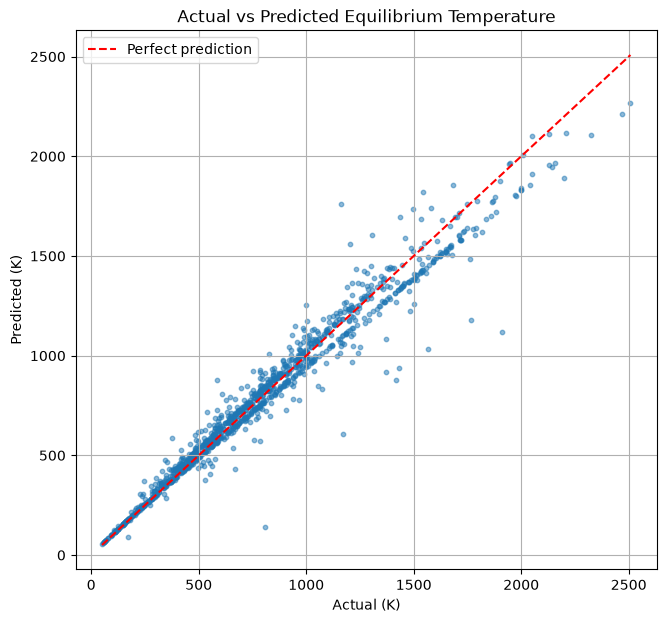

In [17]:
plot_df = pd.DataFrame({
    "Actual (K)": y_test.values,
    "Predicted (K)": np.asarray(test_pred).flatten()
})

ax = plot_df.plot.scatter(
    x="Actual (K)", y="Predicted (K)",
    s=10, alpha=0.5, figsize=(7.5, 7),
    title="Actual vs Predicted Equilibrium Temperature"
)

lims = [plot_df.min().min(), plot_df.max().max()]
ax.plot(lims, lims, "r--", label="Perfect prediction")
ax.legend()
ax.grid(True)

#### The predicted values are close to actual values

### **Predicting hottest and coldest planets**

In [18]:
name_col = "pl_name"

results = pd.DataFrame({
    "planet": df_test[name_col].values,
    "actual_K": y_test.values,
    "predicted_K": np.asarray(test_pred).flatten(),
})

hottest = results.loc[results["predicted_K"].idxmax()]
coldest = results.loc[results["predicted_K"].idxmin()]

print(f"Hottest planet: {hottest['planet']} | Predicted {hottest['predicted_K']:.1f} K | Actual {hottest['actual_K']:.1f} K")
print(f"Coldest planet: {coldest['planet']} | Predicted {coldest['predicted_K']:.1f} K | Actual {coldest['actual_K']:.1f} K")

Hottest planet: WASP-103 b | Predicted 2268.9 K | Actual 2508.0 K
Coldest planet: GJ 849 c | Predicted 55.5 K | Actual 50.4 K


### The model successfully identifies the hottest and coldest planets within the test dataset. The prediction for WASP-103 b underestimates its recorded equilibrium temperature, whereas the prediction for GJ 849 c is relatively close to its actual value. This indicates that the model performs differently across the temperature range and may have greater difficulty estimating certain extreme observations. These are test-set extremes, not necessarily the hottest and coldest planets in the entire NASA catalogue.